# 04 · Genuine NetworkX knowledge graph
The graph supplies ranking features and traceable explanations, not just visualization.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if str(ROOT.parent) not in sys.path: sys.path.insert(0,str(ROOT.parent))
from ml.src.preprocessing import load_data, read_json, save_json
from ml.src.evaluation import evaluate, feature_groups
from ml.src.notebook_helpers import table, metric_row, chart
from IPython.display import display, Code
import matplotlib.pyplot as plt
%matplotlib inline


**Nodes:** workers, historical training tasks, capabilities. **Edges:** worker COMPLETED task (with training outcome), task REQUIRES_CAPABILITY capability, worker HAS_CAPABILITY capability (training counts). Shared `Worker → Task ← Worker` paths define peer weights. Graph score = 0.6×smoothed own capability success + 0.4×co-participant capability prior. Peers are weighted by shared tasks / sqrt(worker task count × peer task count). Only training outcomes annotate graph edges. No test completion edge is created.

In [2]:
from ml.src.knowledge_graph import load_graph, build_graph, graph_features
import networkx as nx
graph=load_graph(ROOT/'models/netease/knowledge_graph.json')
table([read_json('reports/graph_statistics.json')])
display(Code(inspect.getsource(build_graph),language='python'))
display(Code(inspect.getsource(graph_features),language='python'))
sample=list(graph.edges(data=True))[:8]
table([{'From':u,'To':v,**a} for u,v,a in sample])

nodes,edges,node_types,edge_types,training_observations,graph_input
13985,100154,"{'Worker': 1508, 'Task': 12473, 'Capability': 4}","{'COMPLETED': 85647, 'HAS_CAPABILITY': 2034, 'REQUIRES_CAPABILITY': 12473}",85647,training split only


def build_graph(training_rows):
    graph = nx.DiGraph()
    for row in training_rows:
        worker, task, capability = 'worker:'+row['agent_id'], 'task:'+row['task_id'], 'capability:'+row['capability']
        graph.add_node(worker, kind='Worker', source_id=row['agent_id'])
        graph.add_node(task, kind='Task', source_id=row['task_id'])
        graph.add_node(capability, kind='Capability', source_id=row['capability'])
        graph.add_edge(worker, task, relation='COMPLETED', success=row['success'], timestamp=row['timestamp'])
        graph.add_edge(task, capability, relation='REQUIRES_CAPABILITY')
        if not graph.has_edge(worker, capability):
            graph.add_edge(worker, capability, relation='HAS_CAPABILITY', count=0, successes=0)
        edge = graph[worker][capability]
        edge['count'] += 1
        edge['successes'] += row['success']
    return graph

def graph_features(graph, worker_ids, capabilities):
    # Neighbor weights come from actual Worker -> Task <- Worker paths.
    counts, degrees, shared = {}, {}, defaultdict(Counter)
    for node, attrs in graph.nodes(data=True):
        if attrs['kind'] == 'Worker':
            counts[node] = {graph.nodes[v]['source_id']:[e['successes'], e['count']]
                            for _, v, e in graph.out_edges(node, data=True) if e['relation']=='HAS_CAPABILITY'}
            degrees[node] = sum(e['relation']=='COMPLETED' for _, _, e in graph.out_edges(node, data=True))
        elif attrs['kind'] == 'Task':
            participants = [u for u, _, e in graph.in_edges(node, data=True) if e['relation']=='COMPLETED']
            for u in participants:
                shared[u].update(v for v in participants if v != u)
    result = {}
    for worker_id in worker_ids:
        node = 'worker:'+worker_id
        result[worker_id] = {}
        for capability in capabilities:
            successes, count = counts.get(node, {}).get(capability, [0,0])
            own = (successes+2)/(count+4)
            total = weighted = 0.0
            for neighbor, overlap in shared[node].items():
                s, n = counts.get(neighbor, {}).get(capability, [0,0])
                if n:
                    weight = overlap/math.sqrt(max(1,degrees.get(node,0)*degrees.get(neighbor,0)))
                    weighted += weight*(s+2)/(n+4)
                    total += weight
            peer = weighted/total if total else .5
            result[worker_id][capability] = {
                'score': .6*own + .4*peer, 'category_successes':successes,
                'category_count':count, 'neighbor_prior':peer,
                'shared_task_neighbors':len(shared[node]),
                'path':['worker:'+worker_id,'HAS_CAPABILITY','capability:'+capability] if count else []}
    return result

From,To,relation,success,timestamp,count,successes
worker:105,task:987378969294668160,COMPLETED,1,1655897105857,,
worker:105,capability:53,HAS_CAPABILITY,,,789,740
worker:105,task:987378966471901536,COMPLETED,1,1655897036942,,
worker:105,task:987378969068175712,COMPLETED,1,1655897102446,,
worker:105,task:987378967163961728,COMPLETED,1,1655897084856,,
worker:105,task:987378964752236928,COMPLETED,1,1655897085791,,
worker:105,task:987378969978339648,COMPLETED,1,1655897046941,,
worker:105,task:987377742758543744,COMPLETED,1,1655907589518,,


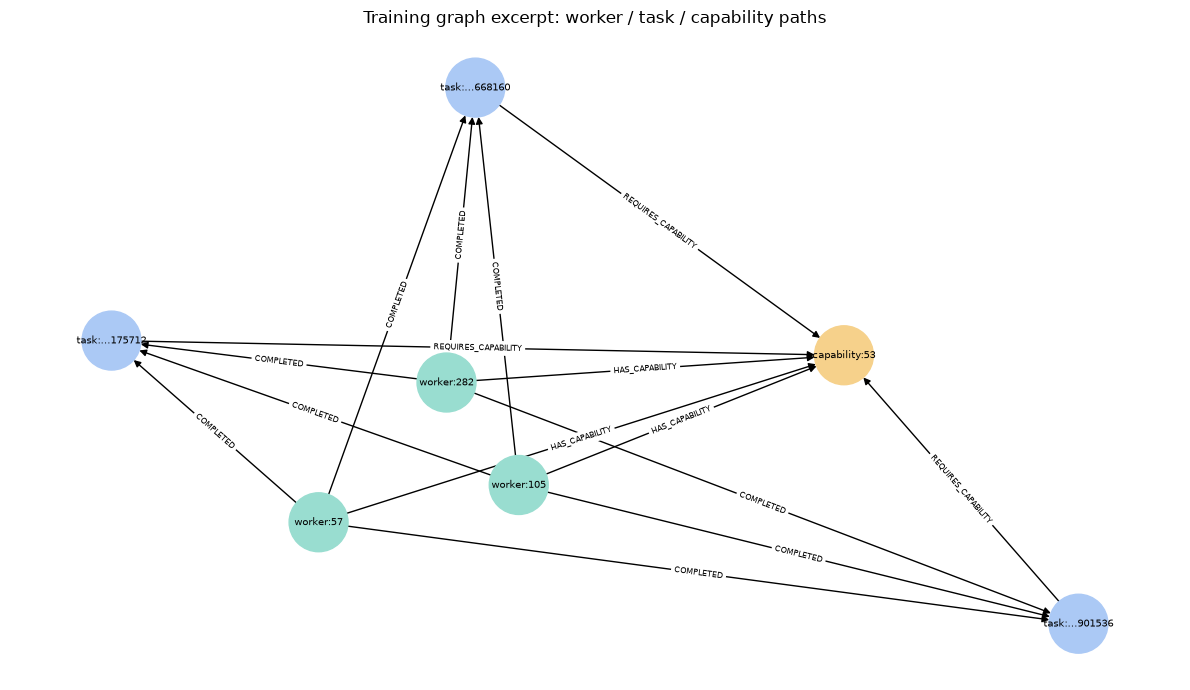

Model,Top-1 %,P@3 %,R@3 %,MAP@3 %,Full MAP %,NDCG@3 %
Knowledge graph / validation,83.697,81.384,65.33,76.96,85.81,82.06


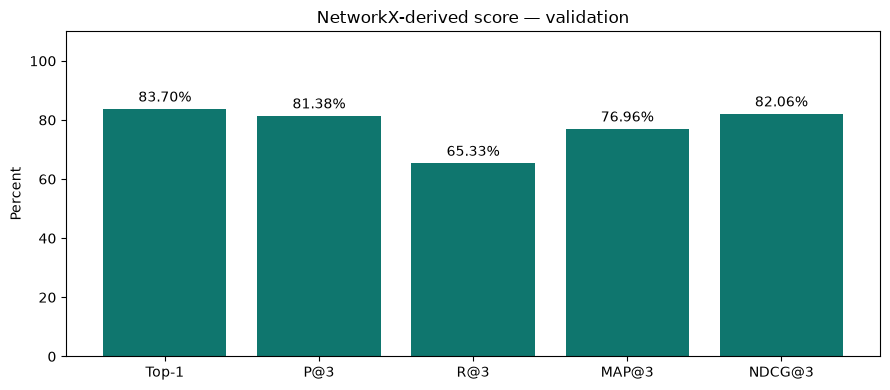

In [3]:
worker=next(n for n,a in graph.nodes(data=True) if a['kind']=='Worker')
tasks=[v for _,v,e in graph.out_edges(worker,data=True) if e['relation']=='COMPLETED'][:3]
nodes={worker,*tasks}
for task in tasks:
    nodes.update(v for _,v in graph.out_edges(task))
    nodes.update(list(graph.predecessors(task))[:3])
small=graph.subgraph(nodes)
fig,ax=plt.subplots(figsize=(12,7))
colors={'Worker':'#99ddd0','Task':'#abc9f5','Capability':'#f6d18b'}
positions=nx.spring_layout(small,seed=42)
labels={n:n if not n.startswith('task:') else 'task:…'+n[-6:] for n in small}
nx.draw_networkx(small,pos=positions,labels=labels,node_color=[colors[small.nodes[n]['kind']] for n in small],node_size=1800,font_size=7,ax=ax,arrows=True)
nx.draw_networkx_edge_labels(small,pos=positions,edge_labels={(u,v):a['relation'] for u,v,a in small.edges(data=True)},font_size=6,ax=ax)
ax.set_title('Training graph excerpt: worker / task / capability paths'); ax.axis('off'); fig.tight_layout()
(ROOT/'reports/figures').mkdir(exist_ok=True); fig.savefig(ROOT/'reports/figures/knowledge_graph.png',dpi=180); plt.show()
groups,splits=load_data()
assert not any('task:'+tid in graph for tid in splits['validation']+splits['test']+splits['purged'])
features=read_json('models/netease/features.json')
result=evaluate(feature_groups(groups,splits['validation'],features),(0,0,1),3)
table([metric_row('Knowledge graph / validation',result)])
chart('NetworkX-derived score — validation',result,'kg.png')